# Phase 9 — Exact fault-type diagnosis results

This notebook presents the saved Phase 9 diagnosis outputs. It does not retrain a model. The diagnosis task is evaluated only on fault-labelled rows, while normal-versus-fault detection remains a separate experiment.

The model predicts the dataset's original fault types directly. No derived fault-group classification is included. Fault labels below the configured minimum support are excluded from diagnosis but retained in the canonical data.

## 1. Load the auditable outputs

The runner writes fold-level summary metrics, per-class metrics, per-building metrics, a confusion matrix, row-level predictions, and a manifest.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RESULTS = ROOT / 'results' / 'diagnosis'

def require_artifacts(*paths):
    missing = [str(path) for path in paths if not path.exists()]
    if missing:
        raise FileNotFoundError('Missing diagnosis outputs. Run Phase 9 first:\n' + '\n'.join(missing))

SUMMARY_PATH = RESULTS / 'diagnosis_metrics_summary.csv'
CLASS_PATH = RESULTS / 'diagnosis_metrics_by_class.csv'
BUILDING_PATH = RESULTS / 'diagnosis_metrics_by_building.csv'
CONFUSION_PATH = RESULTS / 'diagnosis_confusion_matrix.csv'
PREDICTIONS_PATH = RESULTS / 'diagnosis_predictions.csv'
MANIFEST_PATH = RESULTS / 'diagnosis_manifest.json'
require_artifacts(SUMMARY_PATH, CLASS_PATH, BUILDING_PATH, CONFUSION_PATH, PREDICTIONS_PATH, MANIFEST_PATH)

summary = pd.read_csv(SUMMARY_PATH)
by_class = pd.read_csv(CLASS_PATH)
by_building = pd.read_csv(BUILDING_PATH)
confusion = pd.read_csv(CONFUSION_PATH)
manifest = json.loads(MANIFEST_PATH.read_text())
print(f"Loaded {len(summary):,} fold/task rows, {manifest['eligible_fault_row_count']:,} eligible fault rows, and {manifest['excluded_fault_row_count']:,} excluded rare-label rows.")

Loaded 9 fold/task rows, 121,576 eligible fault rows, and 1 excluded rare-label rows.


In [2]:
display(pd.DataFrame({
    'setting': ['Normal label', 'Feature variant', 'Confidence threshold', 'Minimum fault rows', 'Excluded fault labels', 'Evaluation designs'],
    'value': [manifest['normal_label'], ', '.join(manifest['feature_variants']), manifest['confidence_threshold'], manifest['minimum_fault_rows'], ', '.join(manifest['excluded_fault_labels']) or 'none', ', '.join(manifest['designs'])]
}))
display(summary[['design', 'fold', 'task', 'evaluated_rows', 'unsupported_rows', 'coverage', 'macro_f1', 'weighted_f1']].round(3))

,setting,value
0,Normal label,Normal condition
1,Feature variant,physical_signal
2,Confidence threshold,0.7
3,Minimum fault rows,30
4,Excluded fault labels,Cooling supply temperature fault
5,Evaluation designs,"chronological, building_held_out, nested_grouped"


,design,fold,task,evaluated_rows,unsupported_rows,coverage,macro_f1,weighted_f1
0,building_held_out,fold_001,fault_type,8974,44182,0.998,0.991,0.997
1,building_held_out,fold_002,fault_type,12290,0,0.997,0.329,0.317
2,building_held_out,fold_003,fault_type,56130,0,0.993,0.344,0.768
3,chronological,fold_001,fault_type,20958,0,0.985,0.866,0.981
4,nested_grouped,fold_001,fault_type,32473,0,0.955,0.692,0.740
5,nested_grouped,fold_002,fault_type,19733,0,0.985,0.877,0.983
6,nested_grouped,fold_003,fault_type,24433,0,0.998,0.989,0.996
7,nested_grouped,fold_004,fault_type,22626,0,0.997,0.991,0.990
8,nested_grouped,fold_005,fault_type,22311,0,0.998,0.982,0.998


## 2. Overall exact-type performance

The main comparison is macro F1, which gives each fault type equal importance. Weighted F1 is also shown because the dataset is imbalanced. Unsupported rows are not silently counted as ordinary model errors.

In [3]:
overall = (summary.groupby(['design', 'variant', 'task'], as_index=False)
    .agg(folds=('fold', 'nunique'), evaluated_rows=('evaluated_rows', 'sum'),
         unsupported_rows=('unsupported_rows', 'sum'), macro_f1=('macro_f1', 'mean'),
         weighted_f1=('weighted_f1', 'mean'), coverage=('coverage', 'mean'),
         confident_accuracy=('confident_accuracy', 'mean')))
display(overall.round(3))

,design,variant,task,folds,evaluated_rows,unsupported_rows,macro_f1,weighted_f1,coverage,confident_accuracy
0,building_held_out,physical_signal,fault_type,3,77394,44182,0.555,0.694,0.996,0.699
1,chronological,physical_signal,fault_type,1,20958,0,0.866,0.981,0.985,0.989
2,nested_grouped,physical_signal,fault_type,5,121576,0,0.906,0.941,0.987,0.955


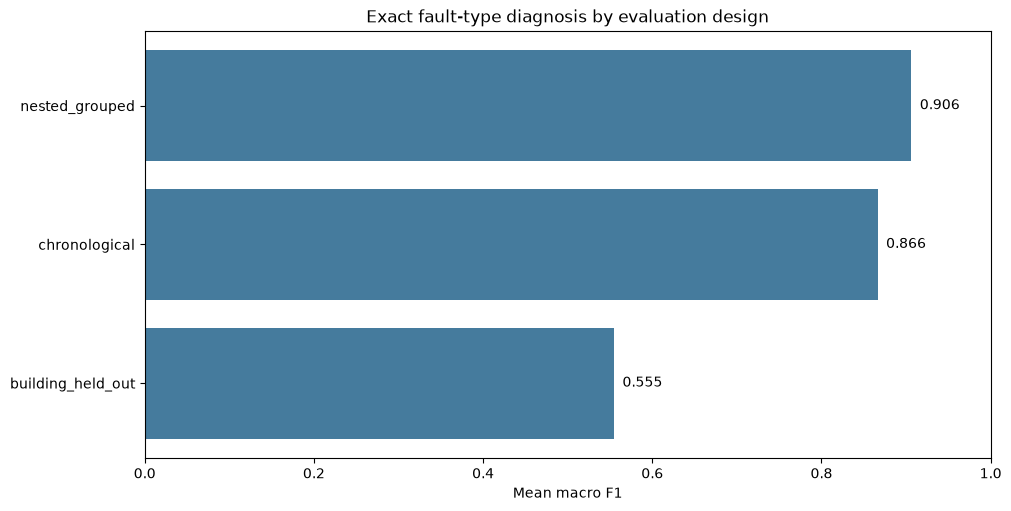

In [4]:
plot_data = overall.sort_values('macro_f1')
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
bars = ax.barh(plot_data['design'], plot_data['macro_f1'], color='#457b9d')
ax.set_xlim(0, 1)
ax.set_xlabel('Mean macro F1')
ax.set_title('Exact fault-type diagnosis by evaluation design')
for bar, value in zip(bars, plot_data['macro_f1']):
    ax.text(value + 0.01, bar.get_y() + bar.get_height() / 2, f'{value:.3f}', va='center')
plt.show()

## 3. Performance by original fault type

These metrics are aggregated across folds using each class's evaluation support as the weight. A blank value means that the class was not evaluated in that design because it was absent from the test data or unsupported by training.

In [5]:
def weighted_class_metrics(frame):
    rows = []
    for label, group in frame.groupby('class_label'):
        supported = group[group['support'] > 0]
        weight = supported['support'].sum()
        if weight == 0:
            rows.append({'class_label': label, 'support': 0, 'precision': np.nan, 'recall': np.nan, 'f1': np.nan})
            continue
        rows.append({
            'class_label': label,
            'support': int(weight),
            'precision': np.average(supported['precision'], weights=supported['support']),
            'recall': np.average(supported['recall'], weights=supported['support']),
            'f1': np.average(supported['f1'], weights=supported['support']),
        })
    return pd.DataFrame(rows)

class_overall = weighted_class_metrics(by_class).sort_values('f1', ascending=False)
display(class_overall.round(3))

,class_label,support,precision,recall,f1
0,Cooling pump fault,19908,1.000,1.000,1.000
1,Heating pump fault,32416,0.940,0.990,0.958
4,Supply fan fault,122945,0.959,0.885,0.911
3,Supply air temperature fault,3039,0.638,0.653,0.643
2,Return air temperature fault,37678,0.819,0.604,0.593
5,Valve position fault,3942,0.371,0.572,0.434


In [6]:
design_class = (by_class.groupby(['design', 'class_label'], as_index=False)
    .apply(lambda group: pd.Series({
        'support': group['support'].sum(),
        'f1': np.average(group.loc[group['support'] > 0, 'f1'], weights=group.loc[group['support'] > 0, 'support']) if (group['support'] > 0).any() else np.nan,
    }), include_groups=False))
design_class = design_class.reset_index(drop=True)
table = design_class.pivot(index='class_label', columns='design', values='f1')
display(table.round(3))

design,building_held_out,chronological,nested_grouped
class_label,,,
Cooling pump fault,NaN,1.000,1.000
Heating pump fault,NaN,0.982,0.951
Return air temperature fault,0.422,0.955,0.712
Supply air temperature fault,0.272,0.959,0.981
Supply fan fault,0.831,0.988,0.977
Valve position fault,0.651,0.313,0.220


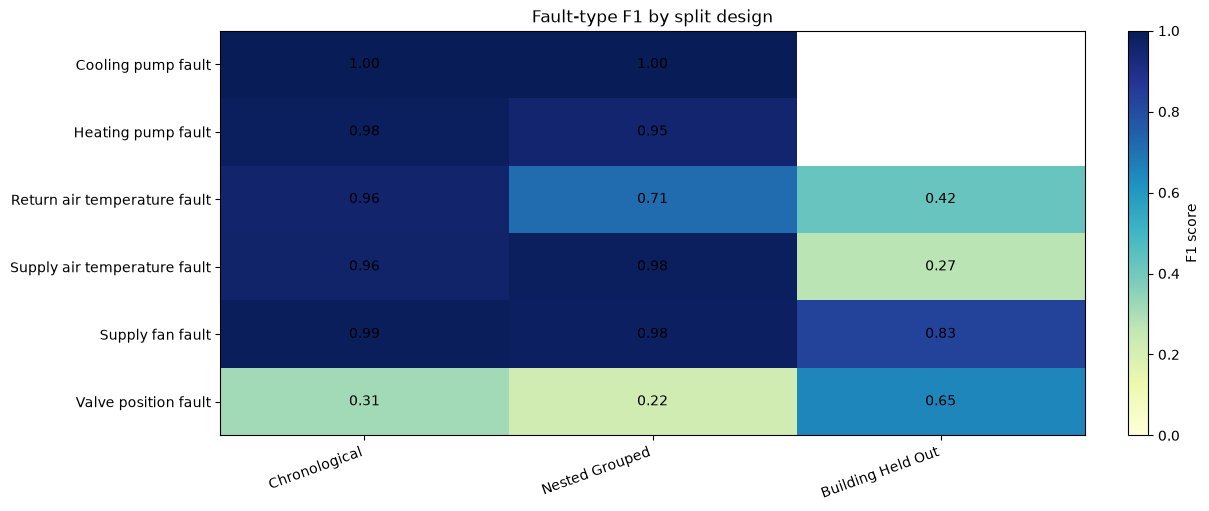

In [7]:
heatmap = table.reindex(columns=['chronological', 'nested_grouped', 'building_held_out'])
fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
image = ax.imshow(heatmap.to_numpy(dtype=float), vmin=0, vmax=1, cmap='YlGnBu', aspect='auto')
ax.set_xticks(range(len(heatmap.columns)), [column.replace('_', ' ').title() for column in heatmap.columns], rotation=20, ha='right')
ax.set_yticks(range(len(heatmap.index)), heatmap.index)
ax.set_title('Fault-type F1 by split design')
for row in range(len(heatmap.index)):
    for column in range(len(heatmap.columns)):
        value = heatmap.iloc[row, column]
        if pd.notna(value):
            ax.text(column, row, f'{value:.2f}', ha='center', va='center', color='black')
fig.colorbar(image, ax=ax, label='F1 score')
plt.show()

## 4. Unsupported classes and confidence coverage

A fault type cannot be learned when it is absent from the training fold. Those rows are reported separately. The confidence threshold is 0.70; the saved confidence is the maximum XGBoost class score, not a calibrated probability.

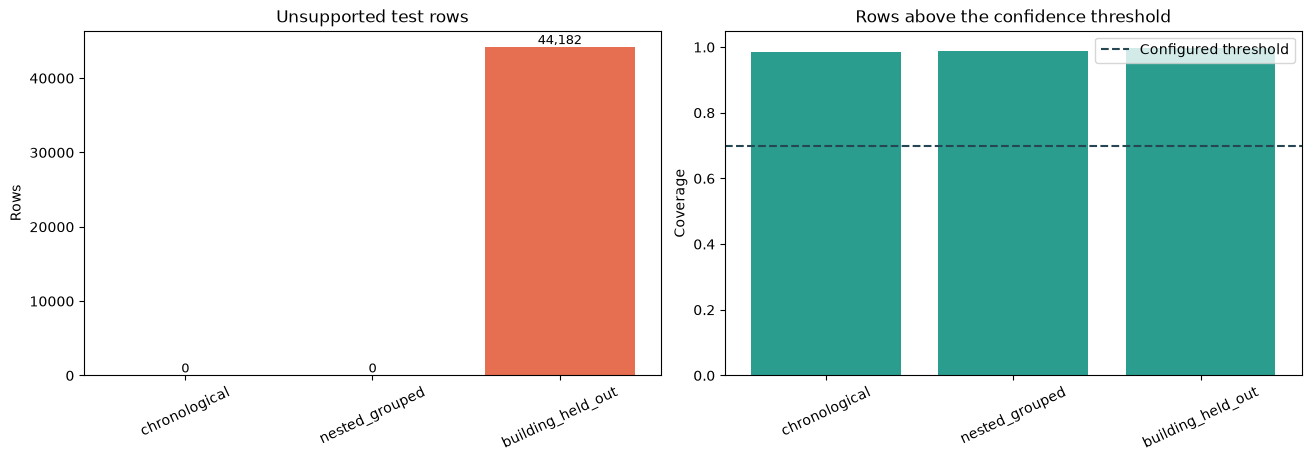

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
plot_data = overall.sort_values('unsupported_rows')
axes[0].bar(plot_data['design'], plot_data['unsupported_rows'], color='#e76f51')
axes[0].set_title('Unsupported test rows')
axes[0].set_ylabel('Rows')
axes[0].tick_params(axis='x', rotation=25)
for index, value in enumerate(plot_data['unsupported_rows']):
    axes[0].text(index, value, f'{value:,}', ha='center', va='bottom', fontsize=9)

axes[1].bar(plot_data['design'], plot_data['coverage'], color='#2a9d8f')
axes[1].axhline(manifest['confidence_threshold'], color='#264653', linestyle='--', label='Configured threshold')
axes[1].set_ylim(0, 1.05)
axes[1].set_title('Rows above the confidence threshold')
axes[1].set_ylabel('Coverage')
axes[1].tick_params(axis='x', rotation=25)
axes[1].legend()
plt.show()

## 5. Confusion matrix for the nested grouped evaluation

The nested grouped design is a useful robustness view because complete AHU groups are held out. Counts are aggregated across its folds.

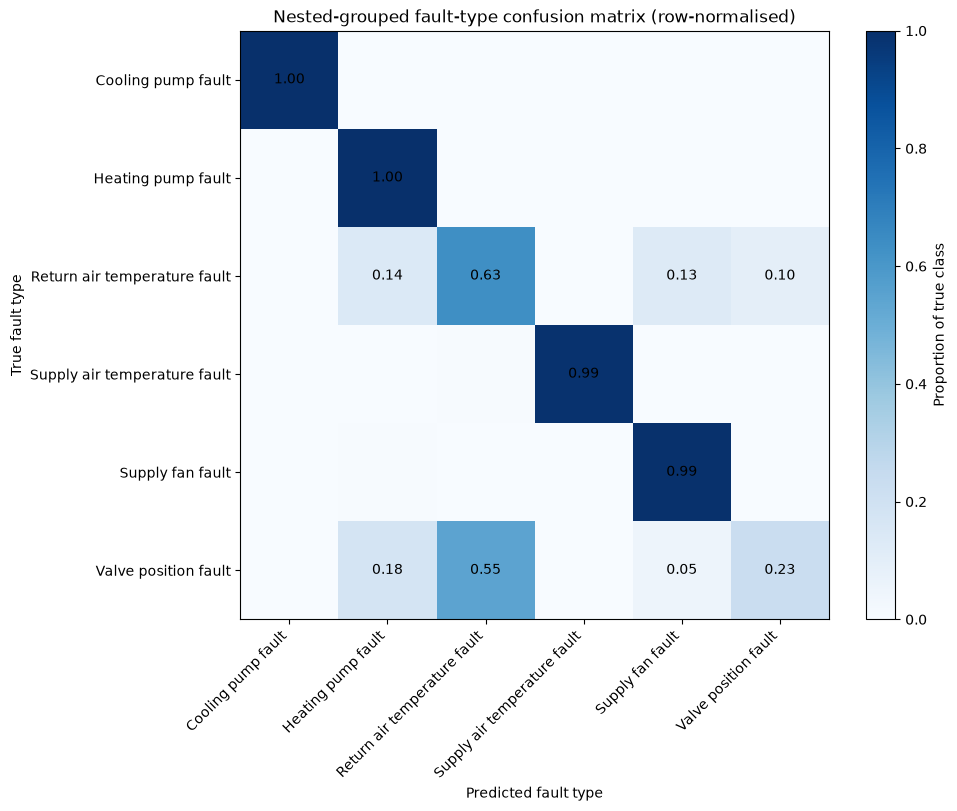

In [9]:
selected = confusion[confusion['design'].eq('nested_grouped')]
matrix = selected.pivot_table(index='true_label', columns='predicted_label', values='count', aggfunc='sum', fill_value=0)
labels = sorted(set(matrix.index) | set(matrix.columns))
matrix = matrix.reindex(index=labels, columns=labels, fill_value=0)
row_totals = matrix.sum(axis=1).replace(0, np.nan)
normalised = matrix.div(row_totals, axis=0)

fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)
image = ax.imshow(normalised.to_numpy(dtype=float), vmin=0, vmax=1, cmap='Blues')
ax.set_xticks(range(len(labels)), labels, rotation=45, ha='right')
ax.set_yticks(range(len(labels)), labels)
ax.set_xlabel('Predicted fault type')
ax.set_ylabel('True fault type')
ax.set_title('Nested-grouped fault-type confusion matrix (row-normalised)')
for row in range(len(labels)):
    for column in range(len(labels)):
        value = normalised.iloc[row, column]
        if pd.notna(value) and value > 0.02:
            ax.text(column, row, f'{value:.2f}', ha='center', va='center')
fig.colorbar(image, ax=ax, label='Proportion of true class')
plt.show()

## 6. Interpretation

The exact-type model is strongest on the chronological and nested-grouped evaluations, while performance drops for a completely unseen building. Supply-fan and pump faults are generally easier to distinguish than valve-position faults. The cooling supply-temperature class has insufficient support for a reliable claim. These results support using the model as an inspection aid rather than an autonomous maintenance decision.